In [1]:
!pip -q install skorch imbalanced-learn kagglehub

In [2]:
import os, copy, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             accuracy_score, recall_score, precision_score, f1_score,
                             classification_report, confusion_matrix)
from skorch import NeuralNetRegressor, NeuralNetClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [3]:
# ---------- One MLP class, configurable ----------
class MLP(nn.Module):
    def __init__(self, n_in, n_out, hidden=64, n_layers=2, dropout=0.0, batchnorm=False):
        super().__init__()
        layers, d = [], n_in
        for _ in range(n_layers):
            layers.append(nn.Linear(d, hidden))
            if batchnorm: layers.append(nn.BatchNorm1d(hidden))
            layers.append(nn.ReLU())
            if dropout > 0: layers.append(nn.Dropout(dropout))
            d = hidden
        layers.append(nn.Linear(d, n_out))      # no activation: raw output / logits
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

# ---------- Data loaders ----------
def make_loader(X, y, task, bs=256, shuffle=False):
    X_t = torch.tensor(X, dtype=torch.float32)
    y_t = torch.tensor(y, dtype=torch.float32 if task == "reg" else torch.long)
    return DataLoader(TensorDataset(X_t, y_t), batch_size=bs, shuffle=shuffle)

# ---------- One pass over a loader ----------
def run_epoch(model, loader, criterion, task, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total, preds, ys = 0.0, [], []
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * len(xb)
            preds.append(out.detach().cpu()); ys.append(yb.cpu())
    preds, ys = torch.cat(preds), torch.cat(ys)
    if task == "reg":
        metric = r2_score(ys.numpy(), preds.numpy())          # R2 = "accuracy" for regression
    else:
        metric = (preds.argmax(1) == ys).float().mean().item()
    return total / len(ys), metric

# ---------- Full training loop ----------
def fit(model, loaders, task, optimizer_cls=torch.optim.Adam, lr=1e-3, epochs=50,
        weight_decay=0.0, patience=None, class_weights=None):
    """loaders: dict with 'train', 'test' and optionally 'val' (used for early stopping only)."""
    model.to(device)
    criterion = nn.MSELoss() if task == "reg" else nn.CrossEntropyLoss(weight=class_weights)
    opt = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {k: [] for k in ["train_loss", "test_loss", "train_metric", "test_metric"]}
    best, best_state, wait = float("inf"), None, 0
    for ep in range(epochs):
        tl, tm = run_epoch(model, loaders["train"], criterion, task, opt)
        sl, sm = run_epoch(model, loaders["test"], criterion, task)
        hist["train_loss"].append(tl); hist["train_metric"].append(tm)
        hist["test_loss"].append(sl);  hist["test_metric"].append(sm)
        if patience and "val" in loaders:                      # early stopping on VALIDATION loss
            vl, _ = run_epoch(model, loaders["val"], criterion, task)
            if vl < best - 1e-6:
                best, best_state, wait = vl, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= patience:
                    print(f"Early stopping at epoch {ep+1}"); break
    if best_state is not None:
        model.load_state_dict(best_state)
    return hist

# ---------- Prediction ----------
def predict(model, X, task):
    model.eval()
    with torch.no_grad():
        out = model(torch.tensor(X, dtype=torch.float32).to(device)).cpu()
    return out.numpy() if task == "reg" else out.argmax(1).numpy()

# ---------- Curves ----------
def plot_history(h, title, metric_name):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["train_loss"], label="Train"); ax[0].plot(h["test_loss"], label="Test")
    ax[0].set_title(f"{title} - Loss / Epochs"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend()
    ax[1].plot(h["train_metric"], label="Train"); ax[1].plot(h["test_metric"], label="Test")
    ax[1].set_title(f"{title} - {metric_name} / Epochs"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel(metric_name); ax[1].legend()
    plt.tight_layout(); plt.savefig(f"{title.replace(' ','_')}.png", dpi=150); plt.show()

PART 1: Regression on NYSE

Step 1.1: Load the data

In [4]:
import kagglehub
nyse_path = kagglehub.dataset_download("dgawlik/nyse")
print(os.listdir(nyse_path))
df = pd.read_csv(os.path.join(nyse_path, "prices-split-adjusted.csv"), parse_dates=["date"])
df.head()

Using Colab cache for faster access to the 'nyse' dataset.
['prices-split-adjusted.csv', 'fundamentals.csv', 'prices.csv', 'securities.csv']


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


Step 1.2: Exploratory Data Analysis (task 1)

(851264, 7)
date      datetime64[ns]
symbol            object
open             float64
close            float64
low              float64
high             float64
volume           float64
dtype: object
           count                           mean                  min  \
date      851264  2013-07-21 02:56:29.294037760  2010-01-04 00:00:00   
open    851264.0                      64.993618                 1.66   
close   851264.0                      65.011913                 1.59   
low     851264.0                      64.336541                  1.5   
high    851264.0                      65.639748                 1.81   
volume  851264.0                 5415112.640027                  0.0   

                        25%                  50%                  75%  \
date    2011-10-19 00:00:00  2013-08-02 00:00:00  2015-04-24 00:00:00   
open                  31.27            48.459999            75.120003   
close             31.292776                48.48            75.139999   
lo

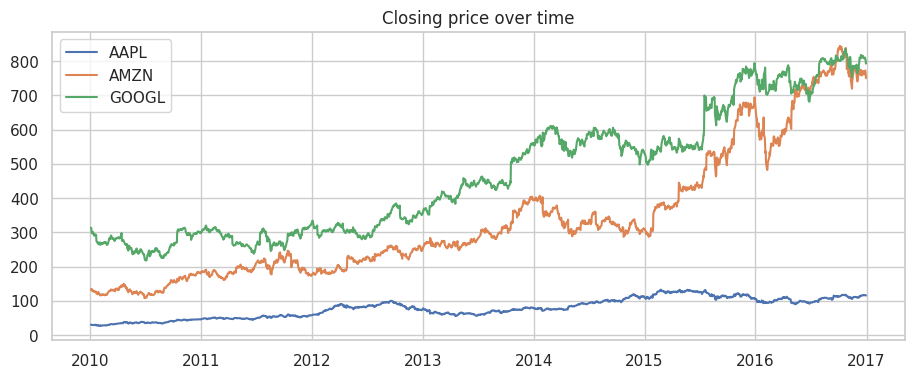

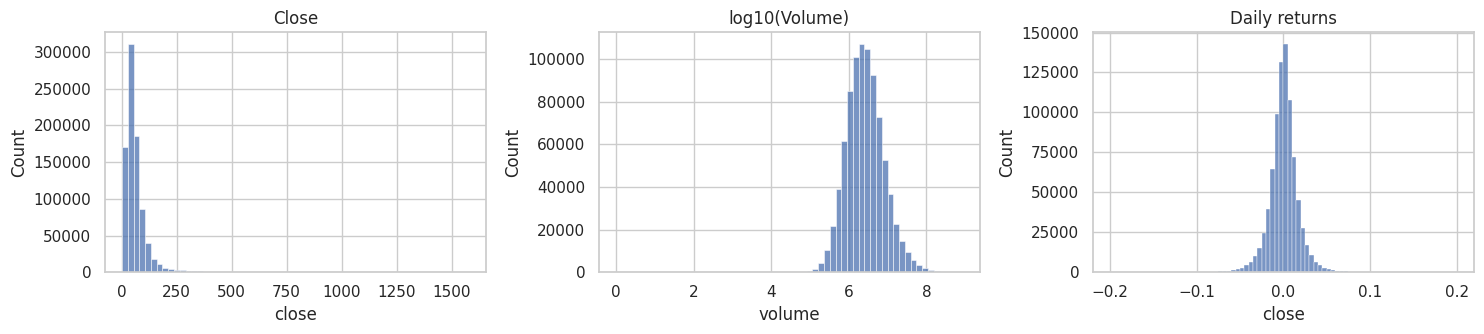

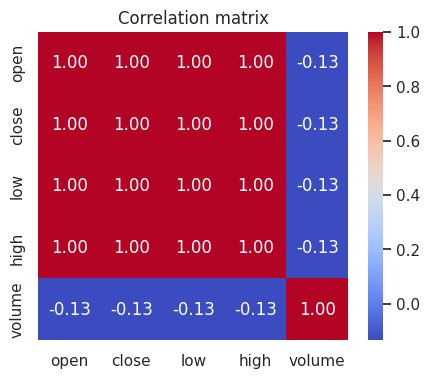

In [5]:
print(df.shape); print(df.dtypes)
print(df.describe().T)
print("Missing values:\n", df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print("Symbols:", df.symbol.nunique(), "| Dates:", df.date.min(), "->", df.date.max())

# 1) Price evolution of a few stocks
fig, ax = plt.subplots(figsize=(11, 4))
for s in ["AAPL", "AMZN", "GOOGL"]:
    if s in df.symbol.values:
        ax.plot(df[df.symbol == s].date, df[df.symbol == s].close, label=s)
ax.set_title("Closing price over time"); ax.legend(); plt.show()

# 2) Distributions (log scale for volume: very skewed)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.histplot(df.close, bins=60, ax=ax[0]);          ax[0].set_title("Close")
sns.histplot(np.log10(df.volume + 1), bins=60, ax=ax[1]); ax[1].set_title("log10(Volume)")
sns.histplot(df.groupby("symbol").close.pct_change().dropna().clip(-0.2, 0.2), bins=80, ax=ax[2])
ax[2].set_title("Daily returns"); plt.tight_layout(); plt.show()

# 3) Correlations
plt.figure(figsize=(5, 4))
sns.heatmap(df[["open", "close", "low", "high", "volume"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix"); plt.show()

Step 1.3: Build the regression problem and preprocess

In [6]:
# Use 20 random stocks to keep GridSearch fast
rng = np.random.RandomState(SEED)
symbols = rng.choice(df.symbol.unique(), 20, replace=False)
d = df[df.symbol.isin(symbols)].sort_values(["symbol", "date"]).copy()

g = d.groupby("symbol")["close"]
d["target"] = g.shift(-1)                                   # tomorrow's close
d["ret_1"]  = g.pct_change()
d["ma5"]    = g.transform(lambda s: s.rolling(5).mean())
d["ma10"]   = g.transform(lambda s: s.rolling(10).mean())
d = d.replace([np.inf, -np.inf], np.nan).dropna().sort_values("date").reset_index(drop=True)

features = ["open", "high", "low", "close", "volume", "ret_1", "ma5", "ma10"]

# TIME-BASED split (never shuffle a time series: it would leak the future into training)
train = d[d.date <  "2016-01-01"]
test  = d[d.date >= "2016-01-01"]

sx, sy = StandardScaler(), StandardScaler()
X_train = sx.fit_transform(train[features]).astype(np.float32)   # fit on TRAIN only
X_test  = sx.transform(test[features]).astype(np.float32)
y_train = sy.fit_transform(train[["target"]]).astype(np.float32)
y_test  = sy.transform(test[["target"]]).astype(np.float32)
print(X_train.shape, X_test.shape)

(27770, 8) (5020, 8)


In [7]:
# Validation set = last 10% (chronologically) of train, used ONLY for early stopping later
n_val = int(0.1 * len(X_train))
loaders_plain = {
    "train": make_loader(X_train, y_train, "reg", shuffle=True),
    "test":  make_loader(X_test,  y_test,  "reg"),
}
loaders_es = {
    "train": make_loader(X_train[:-n_val], y_train[:-n_val], "reg", shuffle=True),
    "val":   make_loader(X_train[-n_val:], y_train[-n_val:], "reg"),
    "test":  make_loader(X_test, y_test, "reg"),
}

Step 1.4: Naive baseline

In [8]:
base_pred = test["close"].values                  # "tomorrow = today"
print("Persistence baseline  RMSE: %.3f  R2: %.4f" % (
      np.sqrt(mean_squared_error(test["target"], base_pred)), r2_score(test["target"], base_pred)))

Persistence baseline  RMSE: 1.663  R2: 0.9992


Step 1.5: GridSearch for the best hyper-parameters (task 3)

In [9]:
net = NeuralNetRegressor(
    module=MLP, module__n_in=X_train.shape[1], module__n_out=1,
    criterion=nn.MSELoss, optimizer=torch.optim.Adam,
    max_epochs=20, lr=1e-3, batch_size=256,
    train_split=None, device=device, verbose=0)

param_grid = {
    "lr": [1e-3, 1e-2],
    "optimizer": [torch.optim.Adam, torch.optim.SGD],
    "max_epochs": [20, 40],
    "module__hidden": [32, 64],
    "module__n_layers": [2, 3],
}

gs = GridSearchCV(net, param_grid, cv=TimeSeriesSplit(n_splits=3),
                  scoring="neg_mean_squared_error", n_jobs=1, verbose=1, refit=False)
gs.fit(X_train, y_train)

print("Best params:", gs.best_params_)
print("Best CV MSE (scaled):", -gs.best_score_)
res = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
res[["params", "mean_test_score", "rank_test_score"]].head(8)

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best params: {'lr': 0.001, 'max_epochs': 40, 'module__hidden': 32, 'module__n_layers': 2, 'optimizer': <class 'torch.optim.adam.Adam'>}
Best CV MSE (scaled): 0.0009642725538772842


,params,mean_test_score,rank_test_score
8,"{'lr': 0.001, 'max_epochs': 40, 'module__hidde...",-0.000964,1
2,"{'lr': 0.001, 'max_epochs': 20, 'module__hidde...",-0.001108,2
12,"{'lr': 0.001, 'max_epochs': 40, 'module__hidde...",-0.001118,3
10,"{'lr': 0.001, 'max_epochs': 40, 'module__hidde...",-0.001137,4
0,"{'lr': 0.001, 'max_epochs': 20, 'module__hidde...",-0.001174,5
4,"{'lr': 0.001, 'max_epochs': 20, 'module__hidde...",-0.001193,6
16,"{'lr': 0.01, 'max_epochs': 20, 'module__hidden...",-0.001265,7
30,"{'lr': 0.01, 'max_epochs': 40, 'module__hidden...",-0.001409,8


Step 1.6: Train the best model and plot the curves (tasks 2 and 4)

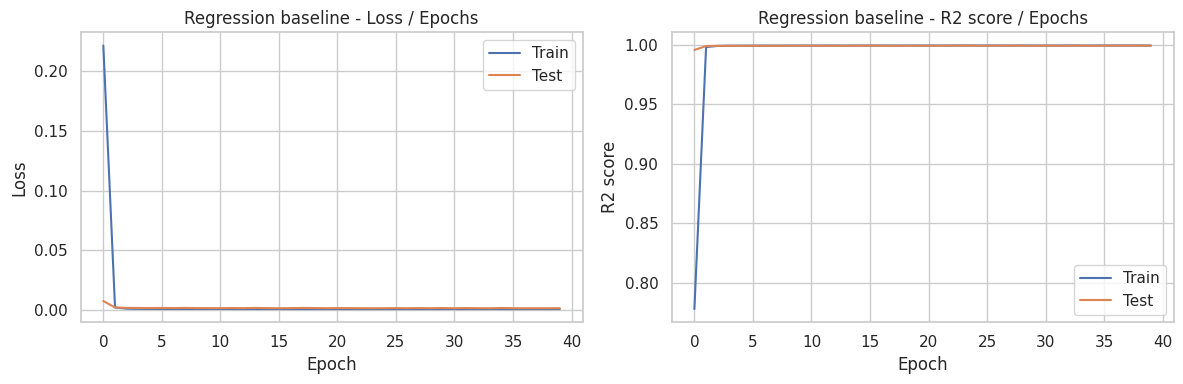

In [10]:
bp = gs.best_params_
set_seed()
model1 = MLP(len(features), 1, hidden=bp["module__hidden"], n_layers=bp["module__n_layers"])
h1 = fit(model1, loaders_plain, "reg", optimizer_cls=bp["optimizer"], lr=bp["lr"], epochs=bp["max_epochs"])
plot_history(h1, "Regression baseline", "R2 score")

In [11]:
def reg_metrics(model, X, y_scaled):
    p = sy.inverse_transform(predict(model, X, "reg")).ravel()
    t = sy.inverse_transform(y_scaled).ravel()
    return {"RMSE ($)": np.sqrt(mean_squared_error(t, p)), "MAE ($)": mean_absolute_error(t, p), "R2": r2_score(t, p)}

res1 = {"Train": reg_metrics(model1, X_train, y_train), "Test": reg_metrics(model1, X_test, y_test)}
pd.DataFrame(res1).T

,RMSE ($),MAE ($),R2
Train,1.27721,0.814160,0.999198
Test,1.76830,1.054606,0.999076


Step 1.7: Regularization (task 5)

Early stopping at epoch 20


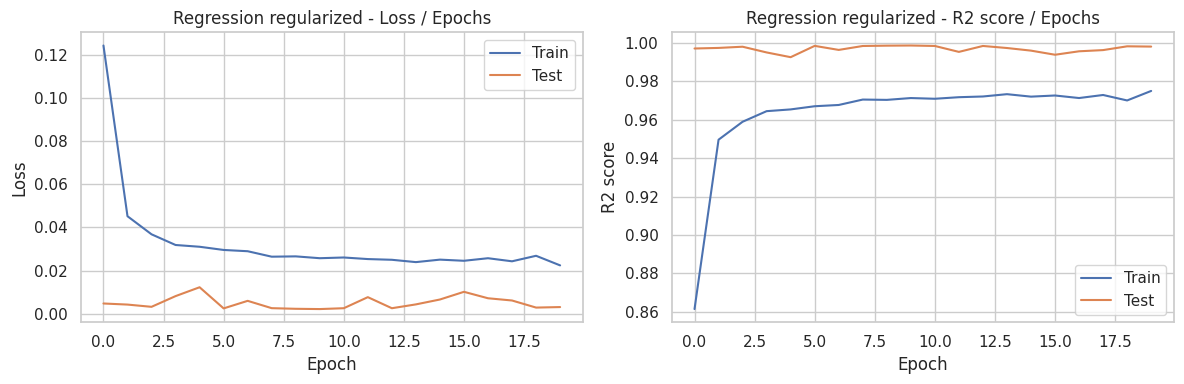

RMSE ($)   MAE ($)        R2
Baseline    Train  1.277210  0.814160  0.999198
            Test   1.768300  1.054606  0.999076
Regularized Train  1.621874  1.131901  0.998706
            Test   2.070832  1.358624  0.998733

In [12]:
set_seed()
model2 = MLP(len(features), 1, hidden=bp["module__hidden"] * 2, n_layers=bp["module__n_layers"],
             dropout=0.2, batchnorm=True)
h2 = fit(model2, loaders_es, "reg", optimizer_cls=torch.optim.AdamW, lr=1e-3, epochs=100,
         weight_decay=1e-3, patience=10)
plot_history(h2, "Regression regularized", "R2 score")

res2 = {"Train": reg_metrics(model2, X_train, y_train), "Test": reg_metrics(model2, X_test, y_test)}
comparison = pd.concat({"Baseline": pd.DataFrame(res1).T, "Regularized": pd.DataFrame(res2).T})
comparison

**PART 2: Multi-class classification (Predictive Maintenance)**

Step 2.1: Load and clean the data (task 1)

In [13]:
pm_path = kagglehub.dataset_download("shivamb/machine-predictive-maintenance-classification")
print(os.listdir(pm_path))
pm = pd.read_csv(os.path.join(pm_path, "predictive_maintenance.csv"))
pm.columns = ["UDI", "Product_ID", "Type", "Air_temp", "Process_temp", "Rot_speed",
              "Torque", "Tool_wear", "Target", "Failure_Type"]       # remove [K], [rpm]... (they break code)
print(pm.shape); print(pm.isna().sum().sum(), "missing |", pm.duplicated().sum(), "duplicates")
print(pm.Failure_Type.value_counts())

Using Colab cache for faster access to the 'machine-predictive-maintenance-classification' dataset.
['predictive_maintenance.csv']
(10000, 10)
0 missing | 0 duplicates
Failure_Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64


In [14]:
# a) Label inconsistencies: Target=1 but "No Failure", or Target=0 but "Random Failures"
bad1 = (pm.Target == 1) & (pm.Failure_Type == "No Failure")
bad2 = (pm.Failure_Type == "Random Failures")
print("Inconsistent rows:", bad1.sum(), "+", bad2.sum())
pm = pm[~(bad1 | bad2)].reset_index(drop=True)      # ~27 rows removed

# b) Drop useless / leaky columns
#    - UDI, Product_ID: identifiers, no predictive meaning
#    - Target: it is just "failure yes/no" = a direct leak of the label
pm = pm.drop(columns=["UDI", "Product_ID", "Target"])

# c) Encode categorical Type (L < M < H quality tiers) as ordinal
pm["Type"] = pm["Type"].map({"L": 0, "M": 1, "H": 2})

Inconsistent rows: 9 + 18


In [16]:
pm["Temp_diff"] = pm.Process_temp - pm.Air_temp                      # heat dissipation
pm["Power"]     = pm.Torque * pm.Rot_speed * 2 * np.pi / 60          # power failures (W)
pm["Strain"]    = pm.Tool_wear * pm.Torque                           # overstrain

Step 2.2: EDA (task 2)

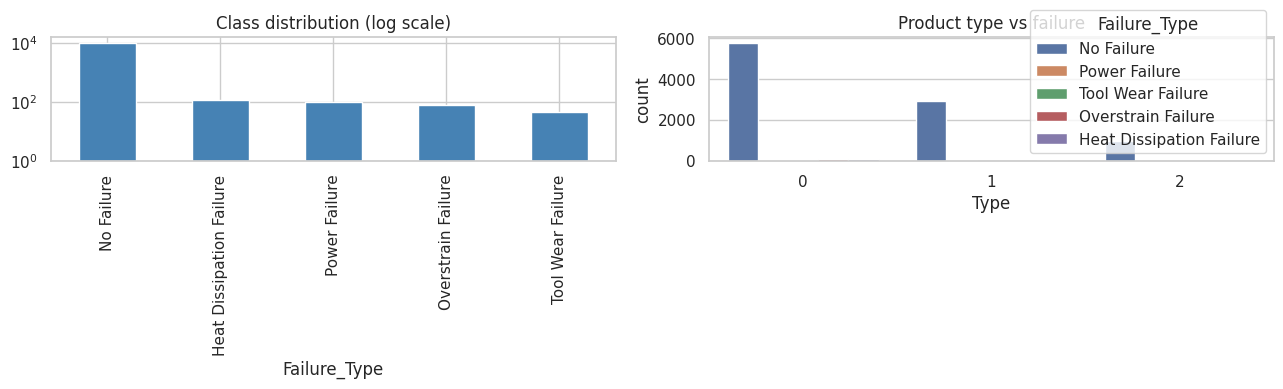

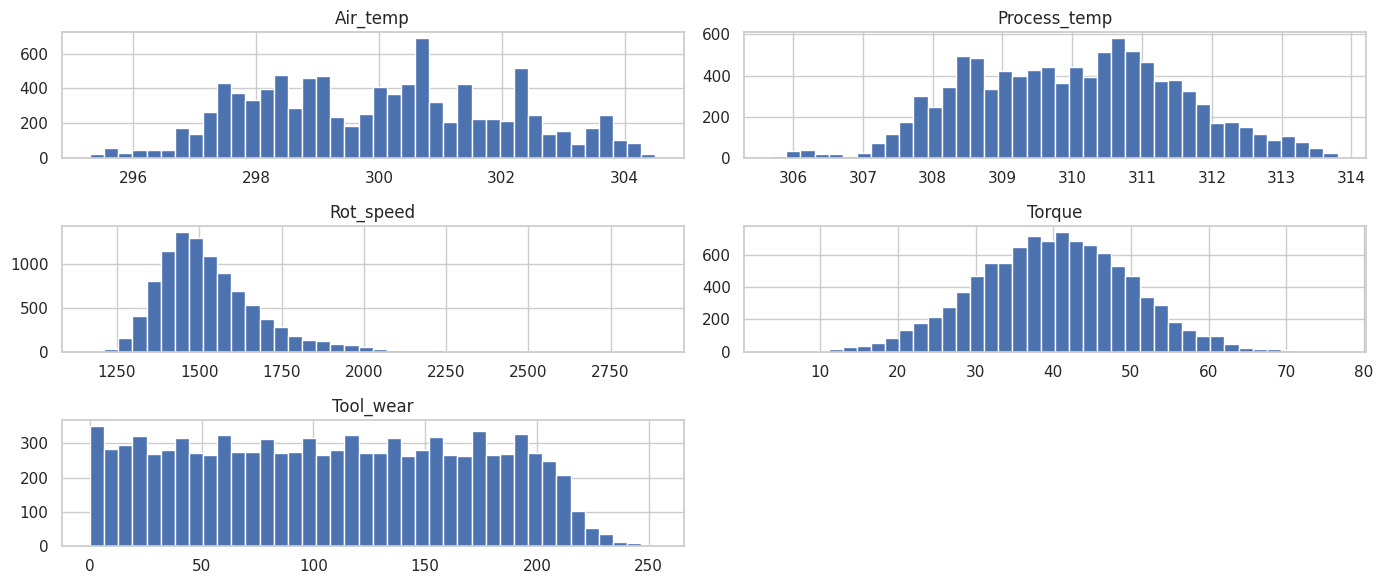

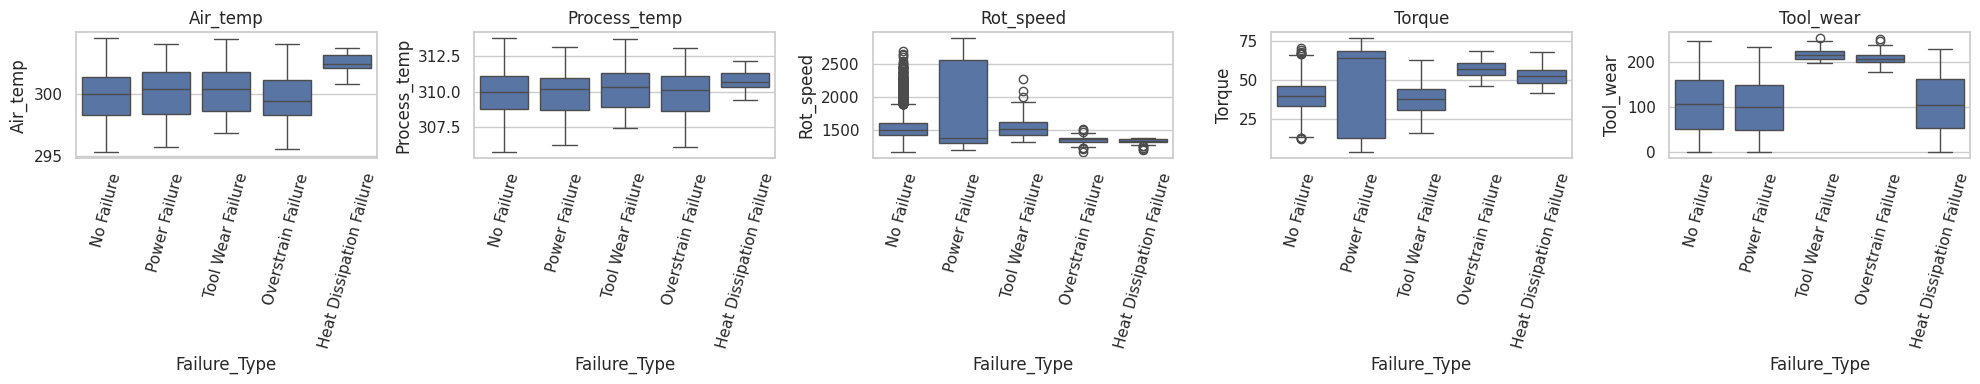

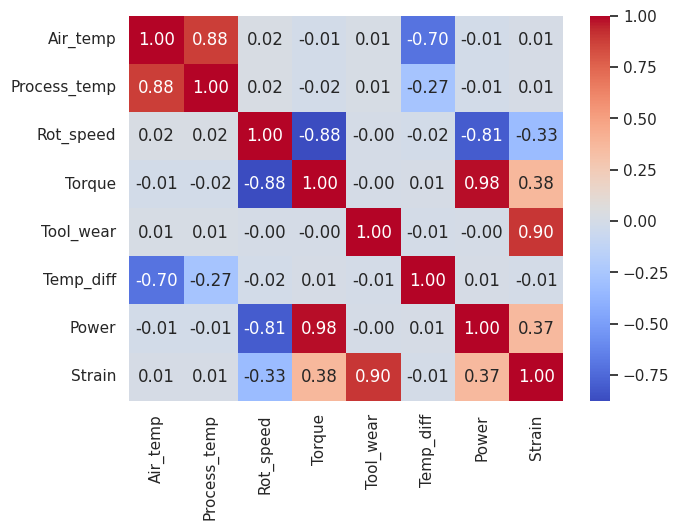

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pm.Failure_Type.value_counts().plot(kind="bar", ax=ax[0], log=True, color="steelblue")
ax[0].set_title("Class distribution (log scale)")
sns.countplot(x="Type", hue="Failure_Type", data=pm, ax=ax[1]); ax[1].set_title("Product type vs failure")
plt.tight_layout(); plt.show()

num_cols = ["Air_temp", "Process_temp", "Rot_speed", "Torque", "Tool_wear"]
pm[num_cols].hist(bins=40, figsize=(14, 6)); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for a, c in zip(ax, num_cols):
    sns.boxplot(x="Failure_Type", y=c, data=pm, ax=a); a.tick_params(axis="x", rotation=75); a.set_title(c)
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(pm[num_cols + ["Temp_diff", "Power", "Strain"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

Step 2.3: Split, scale, then balance the data (tasks 1 and 3)

In [18]:
le = LabelEncoder()
y = le.fit_transform(pm.Failure_Type)
X = pm.drop(columns="Failure_Type")
class_names = le.classes_
print(dict(enumerate(class_names)))

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr).astype(np.float32)     # fit on train only
X_te_s = scaler.transform(X_te).astype(np.float32)
y_tr, y_te = y_tr.astype(np.int64), y_te.astype(np.int64)

# ---- Data augmentation: SMOTE (synthetic minority over-sampling) ----
from imblearn.over_sampling import SMOTE
k = min(5, np.bincount(y_tr).min() - 1)
smote = SMOTE(k_neighbors=k, random_state=SEED)
X_tr_bal, y_tr_bal = smote.fit_resample(X_tr_s, y_tr)
X_tr_bal = X_tr_bal.astype(np.float32); y_tr_bal = y_tr_bal.astype(np.int64)

print("Before:", np.bincount(y_tr)); print("After :", np.bincount(y_tr_bal))

{0: 'Heat Dissipation Failure', 1: 'No Failure', 2: 'Overstrain Failure', 3: 'Power Failure', 4: 'Tool Wear Failure'}
Before: [  90 7714   62   76   36]
After : [7714 7714 7714 7714 7714]


Step 2.4: GridSearch with augmentation done inside the CV folds (tasks 4 and 5)

In [19]:
from imblearn.pipeline import Pipeline as ImbPipeline

clf_net = NeuralNetClassifier(
    module=MLP, module__n_in=X_tr_s.shape[1], module__n_out=len(class_names),
    criterion=nn.CrossEntropyLoss, optimizer=torch.optim.Adam,
    max_epochs=20, lr=1e-3, batch_size=256,
    train_split=None, device=device, verbose=0)

pipe = ImbPipeline([("smote", SMOTE(k_neighbors=2, random_state=SEED)), ("net", clf_net)])

param_grid_clf = {
    "net__lr": [1e-3, 1e-2],
    "net__optimizer": [torch.optim.Adam, torch.optim.SGD],
    "net__max_epochs": [20, 40],
    "net__module__hidden": [32, 64],
    "net__module__n_layers": [2, 3],
}

gs_clf = GridSearchCV(pipe, param_grid_clf, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                      scoring="f1_macro", n_jobs=1, verbose=1, refit=False)
gs_clf.fit(X_tr_s, y_tr)
print("Best params:", gs_clf.best_params_); print("Best CV macro-F1:", gs_clf.best_score_)

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best params: {'net__lr': 0.001, 'net__max_epochs': 40, 'net__module__hidden': 64, 'net__module__n_layers': 3, 'net__optimizer': <class 'torch.optim.adam.Adam'>}
Best CV macro-F1: 0.4253699899676066


Step 2.5: Train the best model and plot curves (task 6)

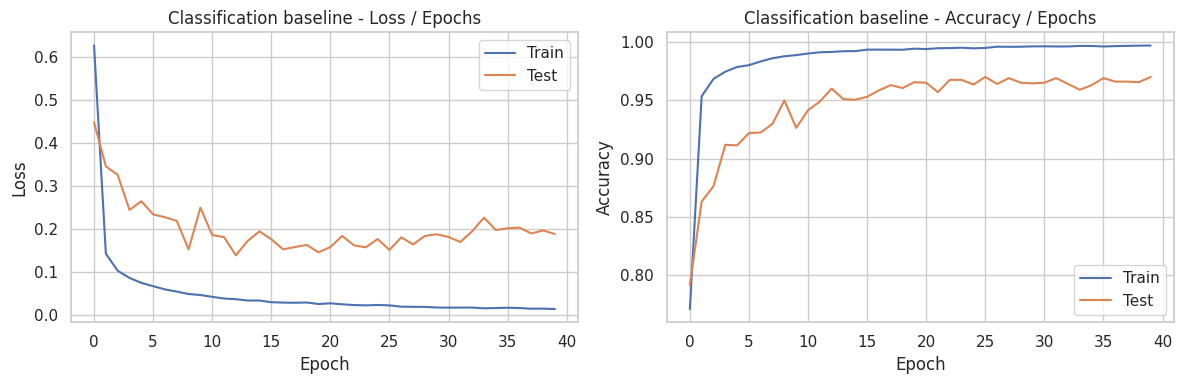

In [20]:
bp2 = gs_clf.best_params_
n_in, n_cls = X_tr_s.shape[1], len(class_names)

loaders_c = {
    "train": make_loader(X_tr_bal, y_tr_bal, "clf", shuffle=True),
    "test":  make_loader(X_te_s,  y_te,  "clf"),
}
set_seed()
clf1 = MLP(n_in, n_cls, hidden=bp2["net__module__hidden"], n_layers=bp2["net__module__n_layers"])
hc1 = fit(clf1, loaders_c, "clf", optimizer_cls=bp2["net__optimizer"], lr=bp2["net__lr"],
          epochs=bp2["net__max_epochs"])
plot_history(hc1, "Classification baseline", "Accuracy")

Step 2.6: Metrics on train and test (task 7)

                          precision    recall  f1-score   support

Heat Dissipation Failure       0.75      0.82      0.78        22
              No Failure       0.99      0.98      0.98      1929
      Overstrain Failure       0.67      0.75      0.71        16
           Power Failure       0.64      0.84      0.73        19
       Tool Wear Failure       0.14      0.44      0.21         9

                accuracy                           0.97      1995
               macro avg       0.64      0.77      0.68      1995
            weighted avg       0.98      0.97      0.97      1995



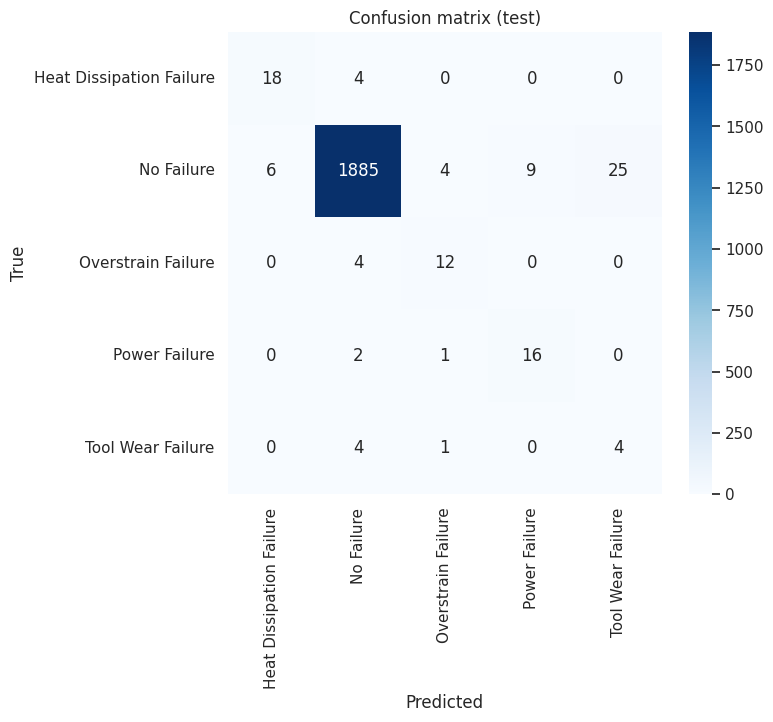

In [21]:
def clf_report(model, X, y, name):
    p = predict(model, X, "clf")
    out = {
        "Accuracy":            accuracy_score(y, p),
        "Sensitivity (macro recall)": recall_score(y, p, average="macro", zero_division=0),
        "Precision (macro)":   precision_score(y, p, average="macro", zero_division=0),
        "F1 (macro)":          f1_score(y, p, average="macro", zero_division=0),
        "F1 (weighted)":       f1_score(y, p, average="weighted", zero_division=0),
    }
    return out, p

# Evaluate on the ORIGINAL (non-augmented) training set and the test set
m_tr, p_tr = clf_report(clf1, X_tr_s, y_tr, "train")
m_te, p_te = clf_report(clf1, X_te_s, y_te, "test")
pd.DataFrame({"Train": m_tr, "Test": m_te})

print(classification_report(y_te, p_te, labels=range(n_cls), target_names=class_names, zero_division=0))

cm = confusion_matrix(y_te, p_te, labels=range(n_cls))
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test)"); plt.show()

Step 2.7: Regularization and comparison (task 8)

Early stopping at epoch 85


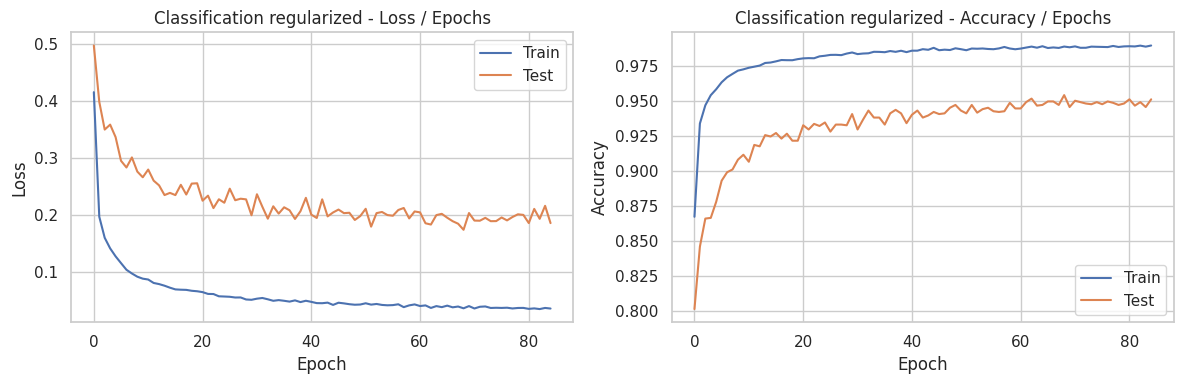

Accuracy  Sensitivity (macro recall)  Precision (macro)  \
Baseline    Train  0.989220                    0.991181           0.810867   
            Test   0.969925                    0.766384           0.637445   
Regularized Train  0.968789                    0.993544           0.702589   
            Test   0.949373                    0.822875           0.604349   

                   F1 (macro)  F1 (weighted)  
Baseline    Train    0.872534       0.990801  
            Test     0.682228       0.974435  
Regularized Train    0.779567       0.977427  
            Test     0.671528       0.963866

In [22]:
n_val = int(0.1 * len(X_tr_bal))
perm = np.random.RandomState(SEED).permutation(len(X_tr_bal))
tr_idx, va_idx = perm[n_val:], perm[:n_val]
# NOTE: validation rows come from the augmented set, a small leak via synthetic neighbors,
# acceptable for early stopping only. Mention it as a limitation.
loaders_c_es = {
    "train": make_loader(X_tr_bal[tr_idx], y_tr_bal[tr_idx], "clf", shuffle=True),
    "val":   make_loader(X_tr_bal[va_idx], y_tr_bal[va_idx], "clf"),
    "test":  make_loader(X_te_s, y_te, "clf"),
}
set_seed()
clf2 = MLP(n_in, n_cls, hidden=bp2["net__module__hidden"] * 2, n_layers=bp2["net__module__n_layers"],
           dropout=0.3, batchnorm=True)
hc2 = fit(clf2, loaders_c_es, "clf", optimizer_cls=torch.optim.AdamW, lr=1e-3, epochs=100,
          weight_decay=1e-3, patience=10)
plot_history(hc2, "Classification regularized", "Accuracy")

m_tr2, _ = clf_report(clf2, X_tr_s, y_tr, "train")
m_te2, p_te2 = clf_report(clf2, X_te_s, y_te, "test")
final = pd.concat({"Baseline": pd.DataFrame({"Train": m_tr, "Test": m_te}).T,
                   "Regularized": pd.DataFrame({"Train": m_tr2, "Test": m_te2}).T})
final

In [ ]:
from google.colab import drive
drive.mount('/content/drive')